# Customer Segmentation using Machine Learning

**Goal:** Segment wholesale distribution customers into distinct groups based on their annual spending across product categories, so the business can design targeted marketing and account strategies for each group (in particular, identify the **high-value customers** worth prioritizing).

**Dataset:** [Wholesale customers dataset](https://archive.ics.uci.edu/dataset/292/wholesale+customers) — 440 customers of a wholesale distributor, with annual spending (in monetary units) on 6 product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicassen.

**Approach:** Data cleaning → EDA → outlier/skew handling → scaling → PCA (for visualization) → K-Means clustering (k chosen via elbow + silhouette) → cluster profiling → business insights.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42


## 2. Load & Inspect the Data

In [2]:
df = pd.read_csv("wholesale_customers.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()

Number of rows: 440
Number of columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [4]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### Data Cleaning
Check for missing values and duplicate records before doing anything else.

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0


The dataset has no missing values or duplicates. However, the spending columns are **strongly right-skewed** (a small number of customers spend far more than the median — see boxplots below), which will distort distance-based clustering. We'll address this with a log transform before scaling.

## 3. Exploratory Data Analysis

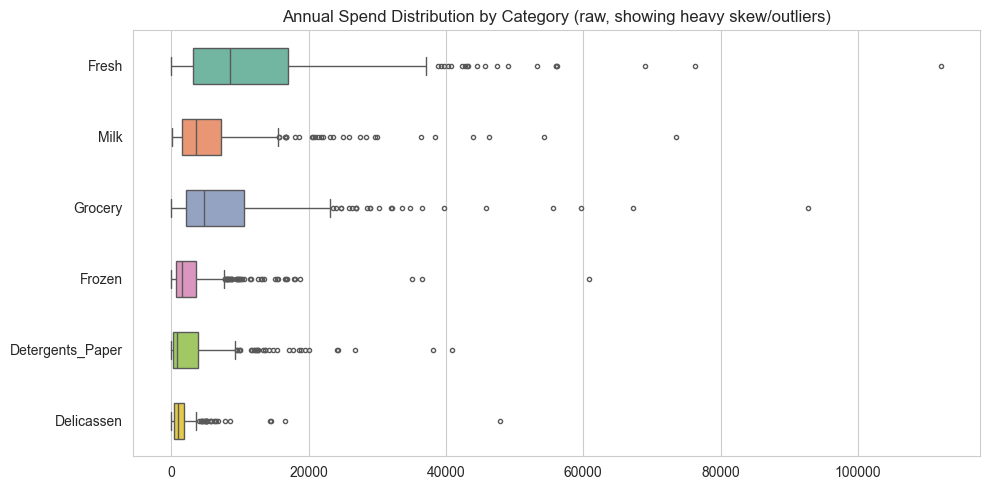

In [6]:
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[spend_cols], orient="h", palette="Set2", width=0.5, fliersize=3, linewidth=1, ax=ax)
ax.set_title("Annual Spend Distribution by Category (raw, showing heavy skew/outliers)")
plt.tight_layout()
plt.show()

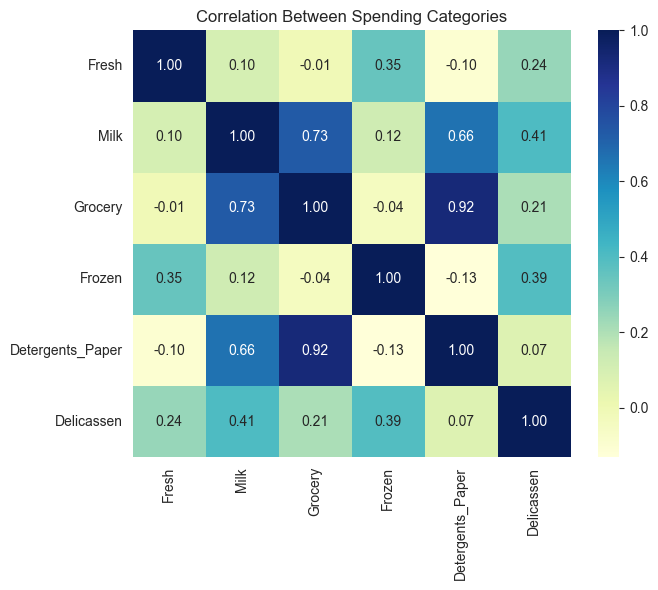

In [7]:
corr_matrix = df[spend_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Correlation Between Spending Categories")
plt.tight_layout()
plt.show()

**Observation:** Grocery and Detergents_Paper are highly correlated (customers who buy a lot of one tend to buy a lot of the other) — likely supermarket/retail-type customers, as opposed to Fresh/Frozen-heavy buyers who look more like restaurants or fresh-food retailers.

## 4. Data Transformation
Log-transform the spending columns to reduce skew and the influence of extreme outliers, then standardize so every category contributes equally to distance calculations (Fresh spend is on a much bigger scale than Delicassen spend, for example).

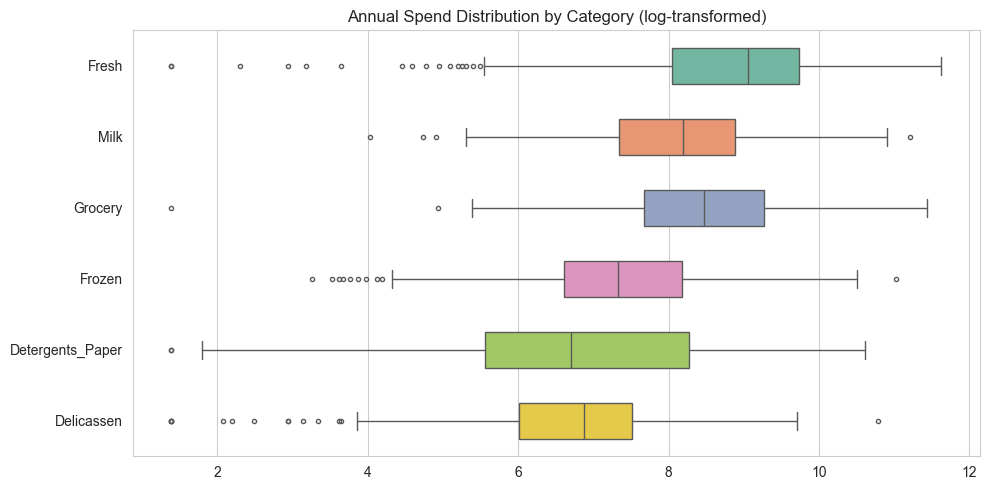

In [8]:
X_log = np.log1p(df[spend_cols])

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=X_log, orient="h", palette="Set2", width=0.5, fliersize=3, linewidth=1, ax=ax)
ax.set_title("Annual Spend Distribution by Category (log-transformed)")
plt.tight_layout()
plt.show()

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

## 5. Dimensionality Reduction (PCA)
PCA is used purely for 2D visualization of the clusters — clustering itself is done on the full scaled feature set so no signal is thrown away.

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance captured by 2 components: {:.1%}".format(pca.explained_variance_ratio_.sum()))

Explained variance ratio: [0.44077752 0.27194917]
Total variance captured by 2 components: 71.3%


## 6. Choosing the Number of Clusters (k)
Rather than picking k arbitrarily, we use the **elbow method** (inertia) and the **silhouette score** across a range of k values.

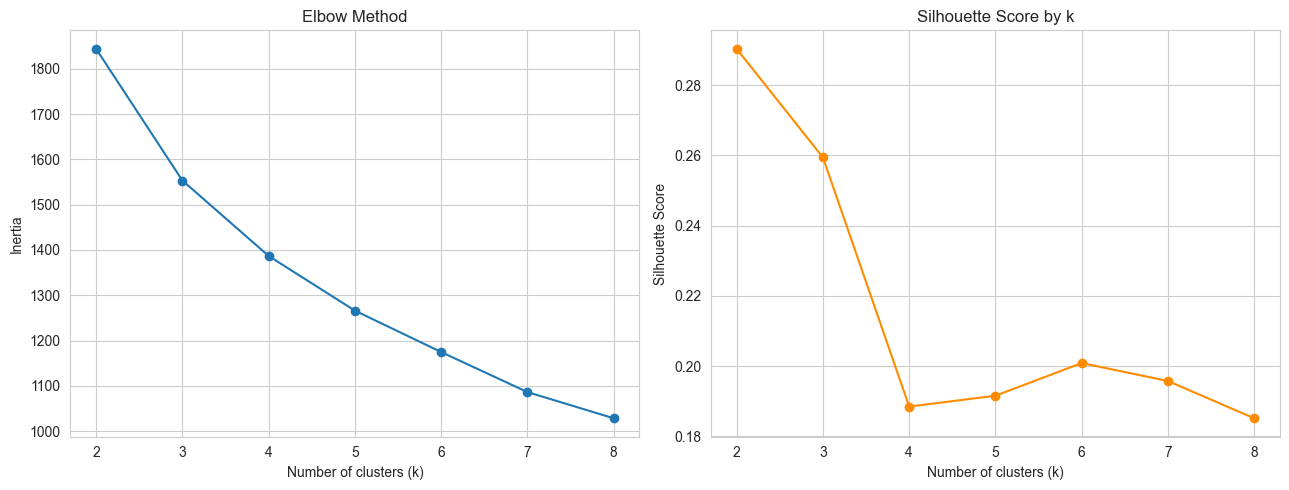

k=2: silhouette=0.290
k=3: silhouette=0.259
k=4: silhouette=0.188
k=5: silhouette=0.192
k=6: silhouette=0.201
k=7: silhouette=0.196
k=8: silhouette=0.185


In [11]:
inertias = []
sil_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_range), sil_scores, marker='o', color='darkorange')
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score by k")

plt.tight_layout()
plt.show()

for k, s in zip(k_range, sil_scores):
    print(f"k={k}: silhouette={s:.3f}")

**Reading the two charts together:**
- The silhouette score is technically highest at k=2. That split mostly just recovers the existing `Channel` column (HoReCa vs. Retail) — mathematically clean, but too coarse to be useful for targeted marketing.
- The elbow chart flattens out from k=4 onward, and k=4 still holds a reasonable silhouette score while producing segments that are distinct enough to act on individually (see cluster profiles below).

We proceed with **k=4**, trading a small amount of silhouette score for business-actionable granularity — a standard judgment call in applied segmentation work, not just the number that maximizes a single metric.

## 7. Train the Final Model

In [12]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df['cluster'] = clusters
df['cluster'].value_counts().sort_index()

cluster
0     61
1    129
2    132
3    118
Name: count, dtype: int64

## 8. Model Evaluation

In [13]:
sil = silhouette_score(X_scaled, clusters)
ch = calinski_harabasz_score(X_scaled, clusters)
print(f"Silhouette score: {sil:.3f}  (closer to 1 = better-separated clusters)")
print(f"Calinski-Harabasz index: {ch:.1f}  (higher = better-separated clusters)")

Silhouette score: 0.188  (closer to 1 = better-separated clusters)
Calinski-Harabasz index: 131.3  (higher = better-separated clusters)


## 9. Visualizing the Clusters

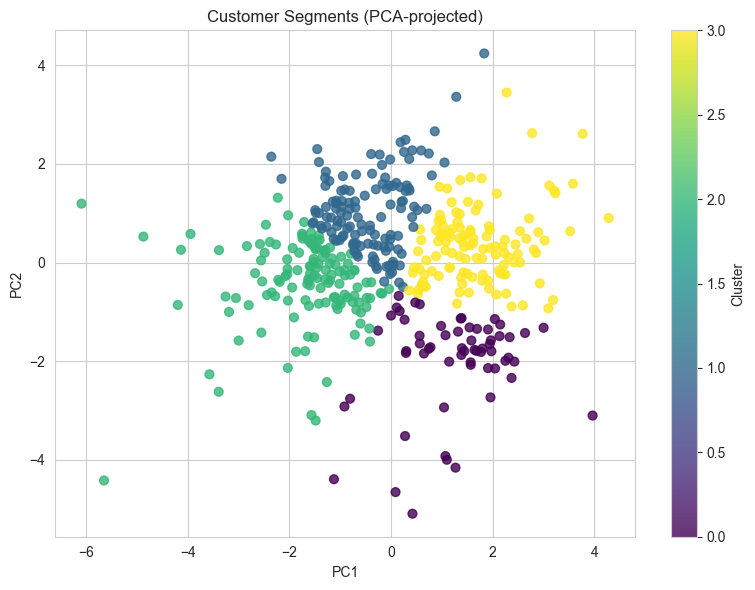

In [14]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=40, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customer Segments (PCA-projected)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [15]:
cluster_profile = df.groupby('cluster')[spend_cols].mean().round(0)
cluster_profile['num_customers'] = df['cluster'].value_counts().sort_index()
cluster_profile['avg_total_spend'] = cluster_profile[spend_cols].sum(axis=1)
cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,num_customers,avg_total_spend
cluster,,,,,,,,
0,2809.0,7062.0,12349.0,566.0,5343.0,636.0,61,28765.0
1,19374.0,4068.0,4445.0,6184.0,723.0,2323.0,129,37117.0
2,9633.0,1570.0,2072.0,2175.0,345.0,585.0,132,16380.0
3,11339.0,11759.0,16088.0,1968.0,6806.0,2164.0,118,50124.0


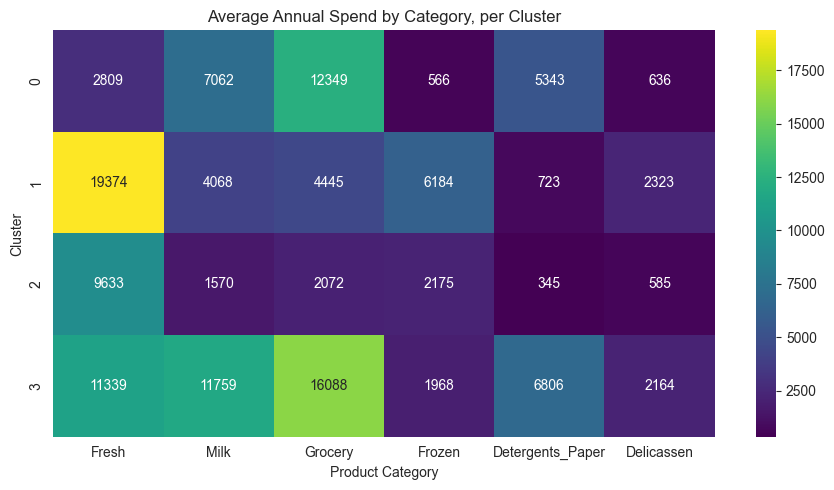

In [16]:
plt.figure(figsize=(9, 5))
sns.heatmap(cluster_profile[spend_cols], cmap='viridis', annot=True, fmt=".0f")
plt.title("Average Annual Spend by Category, per Cluster")
plt.xlabel("Product Category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

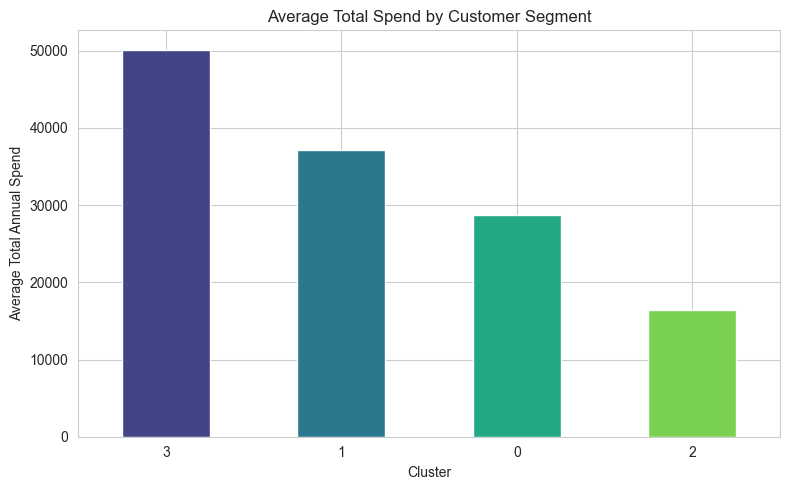

In [17]:
plt.figure(figsize=(8, 5))
cluster_profile['avg_total_spend'].sort_values(ascending=False).plot(kind='bar', color=sns.color_palette('viridis', K))
plt.ylabel("Average Total Annual Spend")
plt.xlabel("Cluster")
plt.title("Average Total Spend by Customer Segment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Identifying the High-Value Segment

In [18]:
high_value_cluster = cluster_profile['avg_total_spend'].idxmax()
print(f"High-value segment: Cluster {high_value_cluster}")
print(f"Average total annual spend: {cluster_profile.loc[high_value_cluster, 'avg_total_spend']:.0f}")
print(f"Number of customers in this segment: {int(cluster_profile.loc[high_value_cluster, 'num_customers'])} "
      f"({int(cluster_profile.loc[high_value_cluster, 'num_customers']) / len(df):.1%} of all customers)")
print()
print("Top spending categories for this segment:")
print(cluster_profile.loc[high_value_cluster, spend_cols].sort_values(ascending=False))

High-value segment: Cluster 3
Average total annual spend: 50124
Number of customers in this segment: 118 (26.8% of all customers)

Top spending categories for this segment:
Grocery             16088.0
Milk                11759.0
Fresh               11339.0
Detergents_Paper     6806.0
Delicassen           2164.0
Frozen               1968.0
Name: 3, dtype: float64


## 11. Business Insights & Recommendations

*(random_state is fixed, so cluster numbers/values below will match your run exactly; run `df.groupby('cluster')[spend_cols].mean()` yourself to double check.)*

Based on the cluster profile table and heatmap above, the four segments read as:

- **High-value / large retail accounts (highest avg. total spend):** Heavy spend across **Grocery, Milk, and Detergents_Paper** — the profile of large supermarket or retail-chain accounts. This is the smallest-to-mid-sized group by count but contributes the most revenue per customer, making it the top priority for dedicated account management, volume-discount retention deals, and loyalty programs.
- **Fresh/Frozen-heavy segment:** Spend is dominated by **Fresh and Frozen** categories relative to everything else — consistent with restaurants, cafes, or fresh-food retailers. This segment is the largest by customer count and responds better to freshness/delivery-speed guarantees than to bulk pricing.
- **Grocery/retail-leaning mid-tier segment:** Moderate, Grocery/Detergents_Paper-leaning spend — smaller, steadier retail-style accounts. Good candidates for cross-sell into Detergents_Paper/Milk given the existing purchasing pattern.
- **Low-spend / occasional segment:** The largest group by customer count but the lowest average spend across every category — likely small or infrequent buyers. Better served through low-cost, automated channels (email promotions, bundle deals) than high-touch account management.

**Actionable takeaway:** Marketing spend and account-manager time should be weighted toward the high-value segment identified programmatically in Section 10, while the low-spend segment (roughly a third of all customers) is served more cost-effectively through automated campaigns rather than one-on-one outreach.

## 12. Conclusion

This project cleaned and transformed the wholesale customer dataset (log transform + scaling to correct for skew), used the elbow method and silhouette analysis to choose and justify k=4 clusters, trained a K-Means model, evaluated it quantitatively (silhouette score, Calinski-Harabasz index), and translated the clusters into concrete business recommendations — identifying the high-value customer segment and proposing a differentiated marketing approach for each group.